# Overview: domain continued pretraining for LGD

Four research questions organize ten analyses. This overview shows the cross-study picture; rq1–rq4 contain the detailed training and benchmark evidence. Benefits depend on model, task and recipe, rather than being uniformly absent or positive.

## 0. Evidence and interpretation

The selected local evidence is a snapshot. Missing evidence remains unavailable; queued VSC jobs are not completed results.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.visualize import style, campaign as cp, questions as rq, synthesis as sy, research_views as rv
from src.visualize import choice_effects as ce, comparisons as cmp, publication as pub, dashboards as db
from src.visualize import diagnostics as dg
from src.visualize import training_summary as ts, pilots as pv, finishing as finish, prediction_diagnostics as pred
from src.visualize.figures import FigureSaver
from src.visualize.inputs import source_description
style.apply()
sink = FigureSaver('general/04_overview_lgd')
report = cp.NotebookReport('Overview: domain continued pretraining for LGD', sink=sink)
print(source_description())
report.add('0. Evidence and interpretation', source_description() + '\n' + 'Four research questions organize ten analyses. This overview shows the cross-study picture; rq1–rq4 contain the detailed training and benchmark evidence. Benefits depend on model, task and recipe, rather than being uniformly absent or positive.')

DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.


## 1. Design, unique evidence and comparability

E1/E3/E4 reuse one 512-run factorial. E9 reuses E8’s exact large-table control. Counts use unique trial identities. Missing extensions and numerical-policy differences remain explicit.

In [2]:
TRACK = 'lgd'
studies = sy.load_studies(TRACK)
credit = sy.catalog(studies, sy.PRIMARY[TRACK])
retention = sy.catalog(studies, sy.PRIMARY[TRACK], domain='ood')
secondary = sy.catalog(studies, sy.SECONDARY[TRACK])
report.table('Four research questions and ten analyses', rv.design_table())
report.table('Unique training inventory', rv.inventory_summary(rv.unique_training_inventory(studies)))
report.table('Recipe and inference comparability', sy.comparability_table(studies))
report.add('1. Design, unique evidence and comparability', 'E1/E3/E4 reuse one 512-run factorial. E9 reuses E8’s exact large-table control. Counts use unique trial identities. Missing extensions and numerical-policy differences remain explicit.')

C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


,experiment,rq,question,result_sources,analysis
0,1,1,Learning rate and training progress,shared/main_grid,Full updates; L2-SP 0.003; all prescribed rates
1,2,1,Training seed sensitivity,"shared/main_grid, experiment2",Matched reference recipes at seeds 42 and 43
2,3,2,L2-SP anchoring,shared/main_grid,"Both L2-SP levels, matched within rate/base/sc..."
3,4,2,Backbone freezing,shared/main_grid,Full/frozen at both L2-SP levels; retain inter...
4,5,2,DiagScale recipe,experiment5,All prescribed rates; recipe-level evaluation
5,6,2,LoRA recipe,experiment6,All prescribed rates; recipe-level evaluation
6,7,3,Row exposure and update weighting,experiment7,"One sample, full pass and accumulation at equa..."
7,8,3,Training corpus composition,experiment8,All versus large PD tables at fixed episode size
8,9,3,Episode size,"experiment8, experiment9",Fixed large-table corpus; shared 8192-row control
9,10,4,Labeled target context,experiment10,Original/CPT and paired difference; fixed comp...


,public_studies,campaign,base,status,unique_trials
0,"1,3,4",cpt_main_v5,TabICLv2,OK,64
1,"1,3,4",cpt_main_v5,TabPFN v2,OK,64
2,"1,3,4",cpt_main_v5,TabPFN v2.6,OK,64
3,"1,3,4",cpt_main_v5,TabPFN v3,OK,64
4,2,cpt_seeds_v5,TabICLv2,OK,4
5,2,cpt_seeds_v5,TabPFN v2,OK,4
6,2,cpt_seeds_v5,TabPFN v2.6,OK,4
7,2,cpt_seeds_v5,TabPFN v3,OK,4
8,5,cpt_diagscale_v1,TabICLv2,OK,12
9,5,cpt_diagscale_v1,TabPFN v3,OK,12


,experiments,study,campaign,arm,bases,learning_rates,l2sp,pd_sampling,training_amp,tabicl_inference,episode_rows,seed,trials
0,"1, 3, 4 (shared)",Main grid,cpt_main_v5,,"TabICLv2, TabPFN v2, TabPFN v2.6, TabPFN v3","3e-07, 1e-06, 1e-05, 3e-05","0, 0.003",uniform rows,True,"FP32, no FA3",measured cap,42,256
1,2,Seed 43,cpt_seeds_v5,,"TabICLv2, TabPFN v2, TabPFN v2.6, TabPFN v3",3e-07,0.003,uniform rows,True,"FP32, no FA3",measured cap,43,16
2,7,Sampling,cpt_sampling_v5,,"TabICLv2, TabPFN v2, TabPFN v2.6, TabPFN v3",3e-07,0.003,uniform rows,True,automatic,measured cap,42,48
3,5,DiagScale,cpt_diagscale_v1,,"TabICLv2, TabPFN v3","0.0001, 0.001, 0.03",0,uniform rows,False,"FP32, no FA3",8192,42,24
4,6,LoRA,cpt_lora_v1,,"TabICLv2, TabPFN v3","1e-05, 0.0001, 0.001",0,uniform rows,True,"FP32, no FA3",measured cap,42,24


## 2. Which models and recipes help?

All prescribed follow-up arms are shown alongside the predefined main reference and its frozen counterpart. No row is selected by its test outcome. Individual-table gains accompany corpus summaries in the RQ results notebooks.

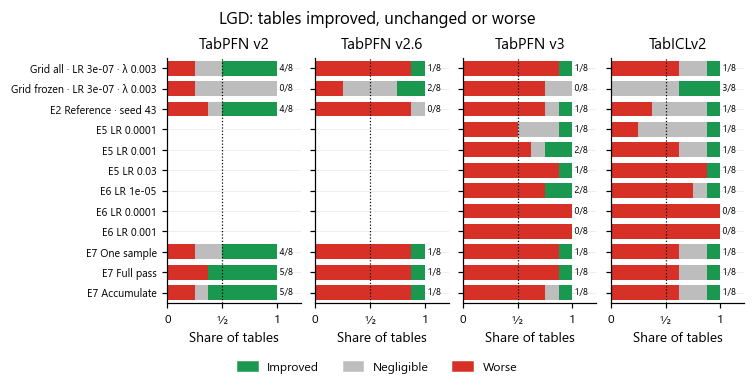

LGD. For the predefined full/frozen reference and all prescribed follow-up arms, the share of held-out credit tables whose paired R² change relative to the original model exceeds +0.001  (improved), lies within ±0.001 (negligible) or falls below −0.001 (worse); numbers give improved/total tables. The ±0.001 band is a reporting convention for this study, not a statistical equivalence margin. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. The dotted line marks half of the tables.

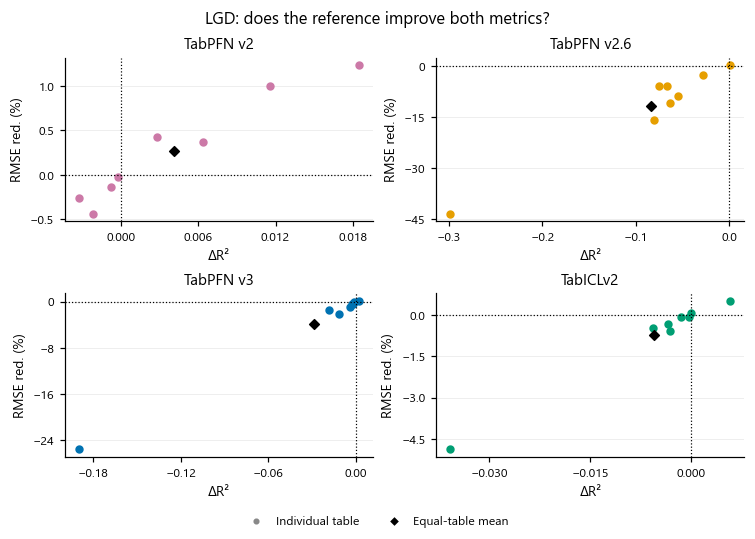

LGD. The predefined full-update reference (peak LR 3e-7, L2-SP 0.003, seed 42) on held-out credit tables. Horizontal values are ΔR²; vertical values are RMSE reduction (%). Each colored point represents one table with five complete paired outer folds for both metrics; the diamond is their equal-table mean. Both directions are oriented so that positive favors CPT. Axis ranges differ by base to retain small effects. R² and RMSE derive from squared error and are not independent confirmations; relative RMSE puts the size of error changes in context. 

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0,TabICLv2,r2,8,0.531911,0.518848,-0.013063,...,-0.016541,-0.009752,-0.027213,-0.000744,0,1,7,6,40,0.000
1,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0,TabPFN v2,r2,8,0.474518,0.471931,-0.002587,...,-0.003056,0.000372,-0.016598,0.002459,2,2,4,11,40,0.250
2,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0,TabPFN v2.6,r2,8,0.539808,0.509451,-0.030357,...,-0.033437,-0.011231,-0.100926,-0.003111,0,0,8,4,40,0.000
3,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0,TabPFN v3,r2,8,0.539412,0.413691,-0.125721,...,-0.118124,-0.040205,-0.510554,-0.005094,0,0,8,0,40,0.000
4,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0.003,TabICLv2,r2,8,0.531911,0.512814,-0.019097,...,-0.019401,-0.008748,-0.072084,-0.000106,0,1,7,7,40,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87,8,LoRA,LoRA,E6 LR 0.0001,TabPFN v3,r2,8,0.539412,0.354608,-0.184804,...,-0.238554,-0.070468,-0.531193,-0.019110,0,0,8,2,40,0.000
88,8,LoRA,LoRA,E6 LR 0.001,TabICLv2,r2,8,0.531911,0.382768,-0.149143,...,-0.165468,-0.095844,-0.347297,-0.051982,0,0,8,0,40,0.000
89,8,LoRA,LoRA,E6 LR 0.001,TabPFN v3,r2,8,0.539412,0.346687,-0.192724,...,-0.242109,-0.075387,-0.466831,-0.039394,0,0,8,0,40,0.000
90,8,LoRA,LoRA,E6 LR 1e-05,TabICLv2,r2,8,0.531911,0.498942,-0.032969,...,-0.031165,-0.003511,-0.162845,0.001844,1,1,6,6,40,0.125


,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0,TabICLv2,rmse,8,0.224874,0.228396,-0.018905,...,-0.024884,-0.008044,-0.045472,-0.001025,0,0,8,6,40,0.000
1,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0,TabPFN v2,rmse,8,0.240824,0.241534,-0.002828,...,-0.002270,-0.000776,-0.013997,0.001212,1,2,5,11,40,0.125
2,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0,TabPFN v2.6,rmse,8,0.221788,0.229092,-0.033603,...,-0.057364,-0.018287,-0.065394,-0.002578,0,0,8,4,40,0.000
3,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0,TabPFN v3,rmse,8,0.222704,0.254599,-0.148933,...,-0.161782,-0.032218,-0.598692,-0.011148,0,0,8,0,40,0.000
4,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0.003,TabICLv2,rmse,8,0.224874,0.230291,-0.026503,...,-0.026739,-0.009784,-0.096150,0.000146,0,1,7,7,40,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87,8,LoRA,LoRA,E6 LR 0.0001,TabPFN v3,rmse,8,0.222704,0.264947,-0.193147,...,-0.234261,-0.065050,-0.618201,-0.028454,0,0,8,2,40,0.000
88,8,LoRA,LoRA,E6 LR 0.001,TabICLv2,rmse,8,0.224874,0.260857,-0.174559,...,-0.230501,-0.103745,-0.404005,-0.032568,0,0,8,0,40,0.000
89,8,LoRA,LoRA,E6 LR 0.001,TabPFN v3,rmse,8,0.222704,0.268034,-0.222710,...,-0.299529,-0.076233,-0.556411,-0.044404,0,0,8,0,40,0.000
90,8,LoRA,LoRA,E6 LR 1e-05,TabICLv2,rmse,8,0.224874,0.233991,-0.038842,...,-0.039891,-0.002487,-0.206427,0.001977,1,0,7,6,40,0.125


In [3]:
cp.show(sink, sy.plot_outcomes(credit, TRACK), track=TRACK)
cp.show(sink, rv.plot_secondary_effects(credit, secondary, TRACK), track=TRACK)
report.table('Primary metric: original, CPT, effect and heterogeneity', sy.summarize(credit))
report.table('Secondary metric: original, CPT, effect and heterogeneity', sy.summarize(secondary))
report.add('2. Which models and recipes help?', 'All prescribed follow-up arms are shown alongside the predefined main reference and its frozen counterpart. No row is selected by its test outcome. Individual-table gains accompany corpus summaries in the RQ results notebooks.')

## 3. Transfer, retention and measured adaptation cost

Credit transfer and four-table non-credit retention are evaluated separately. Historical GPU-hours exclude queueing and benchmark inference; hardware/runtime differences limit timing comparisons. Adapter comparisons concern complete recipes.

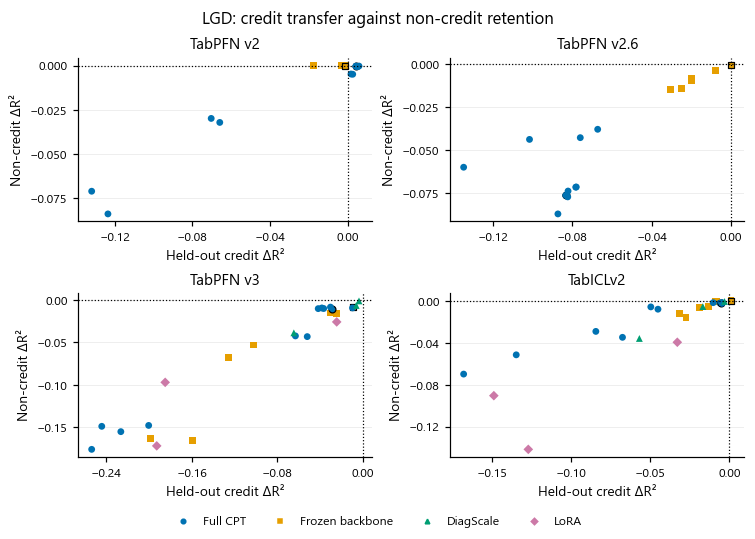

LGD. Each point is one configuration: its equal-table mean paired change on held-out credit tables (horizontal) and on the four non-credit retention tables of the same task (vertical), both relative to the original model of the same base. Non-credit tables first average all four CPT training partitions. The upper-right quadrant improves both; the lower-right gains on credit while losing on the retention panel. Points outlined in black are the experiment-1 reference recipes (full and frozen). Axis limits differ between models. A four-table retention panel does not establish general retention. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. 

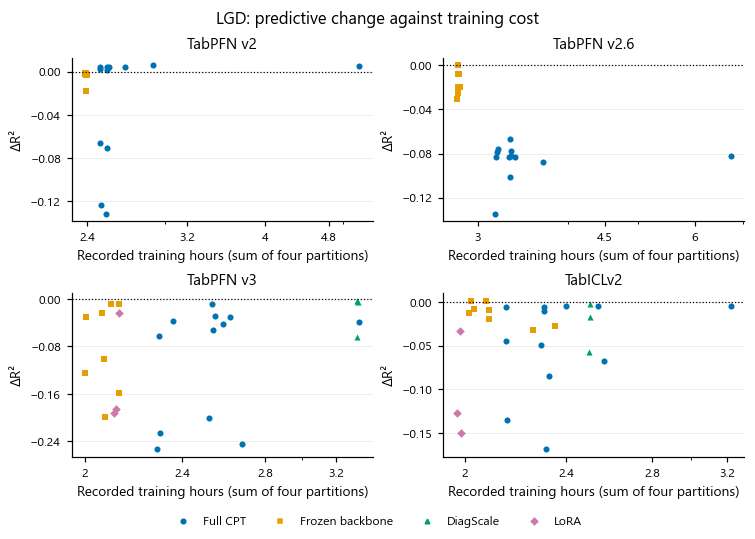

LGD. Each point is one configuration: its equal-table mean paired change in R² on held-out credit tables against recorded training time summed over the four CPT partitions (logarithmic axis). Training time excludes evaluation and queueing and was recorded on the GPUs used for each study, so it is an observed cost, not a matched-compute comparison. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. 

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0,TabICLv2,r2,4,0.904621,0.899004,-0.005617,...,-0.008772,-0.002309,-0.009385,-0.002151,0,0,4,5,80,0.0
1,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0,TabPFN v2,r2,4,0.876377,0.876424,0.000047,...,-0.000024,0.000106,-0.000148,0.000269,0,4,0,37,80,0.0
2,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0,TabPFN v2.6,r2,4,0.900482,0.885543,-0.014939,...,-0.017835,-0.012602,-0.020598,-0.008163,0,0,4,0,80,0.0
3,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0,TabPFN v3,r2,4,0.908113,0.840367,-0.067746,...,-0.105519,-0.019300,-0.142870,-0.013968,0,0,4,1,80,0.0
4,1,Main grid,Frozen backbone,Grid frozen · LR 1e-05 · λ 0.003,TabICLv2,r2,4,0.904621,0.898041,-0.006580,...,-0.009760,-0.001885,-0.014554,-0.001636,0,0,4,8,80,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87,8,LoRA,LoRA,E6 LR 0.0001,TabPFN v3,r2,4,0.908111,0.810891,-0.097219,...,-0.103488,-0.053573,-0.217261,-0.051933,0,0,4,0,80,0.0
88,8,LoRA,LoRA,E6 LR 0.001,TabICLv2,r2,4,0.904621,0.814191,-0.090430,...,-0.098282,-0.048356,-0.207945,-0.041357,0,0,4,0,80,0.0
89,8,LoRA,LoRA,E6 LR 0.001,TabPFN v3,r2,4,0.908111,0.736015,-0.172096,...,-0.181294,-0.122210,-0.309933,-0.115634,0,0,4,0,80,0.0
90,8,LoRA,LoRA,E6 LR 1e-05,TabICLv2,r2,4,0.904621,0.865115,-0.039506,...,-0.060498,-0.002972,-0.107322,-0.002771,0,0,4,4,80,0.0


,base,learning_rate,l2sp_lambda,frozen,sampling,experiment,arm,gpu_hours,partitions
0,TabICLv2,3.000000e-07,0.000,False,one_sample,1,None,2.153376,4
1,TabICLv2,3.000000e-07,0.000,True,one_sample,1,None,2.022735,4
2,TabICLv2,3.000000e-07,0.003,False,one_sample,1,None,2.306132,4
3,TabICLv2,3.000000e-07,0.003,True,one_sample,1,None,2.078621,4
4,TabICLv2,1.000000e-06,0.000,False,one_sample,1,None,2.154600,4
...,...,...,...,...,...,...,...,...,...
87,TabICLv2,1.000000e-04,0.000,False,one_sample,8,None,1.970989,4
88,TabICLv2,1.000000e-03,0.000,False,one_sample,8,None,1.985072,4
89,TabPFN v3,1.000000e-05,0.000,False,one_sample,8,None,2.132650,4
90,TabPFN v3,1.000000e-04,0.000,False,one_sample,8,None,2.120248,4


In [4]:
cp.show(sink, sy.plot_transfer_retention(credit, retention, TRACK), track=TRACK)
cp.show(sink, sy.plot_cost_effect(credit, sy.costs(studies), TRACK), track=TRACK)
report.table('Non-credit retention', sy.summarize(retention))
report.table('Recorded costs', sy.costs(studies))
report.add('3. Transfer, retention and measured adaptation cost', 'Credit transfer and four-table non-credit retention are evaluated separately. Historical GPU-hours exclude queueing and benchmark inference; hardware/runtime differences limit timing comparisons. Adapter comparisons concern complete recipes.')

## 4. Main findings and reading guide

RQ1 links learning rates with training-seed stability; RQ2 retains anchoring/freezing interactions and all adapter recipes; RQ3 separates sampling, corpus and episode effects; RQ4 shows original/CPT context curves and paired differences with fixed complete test rows. Numerical precision, table heterogeneity and overlapping training corpora bound the conclusions.

In [5]:
conclusions = sy.findings(credit, TRACK)
print(conclusions)
report.table('All primary named-table effects', credit)
report.table('All secondary named-table effects', secondary)
report.add('4. Main findings and reading guide', conclusions + '\n' + 'RQ1 links learning rates with training-seed stability; RQ2 retains anchoring/freezing interactions and all adapter recipes; RQ3 separates sampling, corpus and episode effects; RQ4 shows original/CPT context curves and paired differences with fixed complete test rows. Numerical precision, table heterogeneity and overlapping training corpora bound the conclusions.')

Reference recipe, TabICLv2: mean -0.0055 R², median -0.0023, 1/8 tables improved, 5 worse (original 0.5319 → adapted 0.5264).
Reference recipe, TabPFN v2: mean +0.0041 R², median +0.0013, 4/8 tables improved, 2 worse (original 0.4745 → adapted 0.4786).
Reference recipe, TabPFN v2.6: mean -0.0832 R², median -0.0647, 1/8 tables improved, 7 worse (original 0.5398 → adapted 0.4566).
Reference recipe, TabPFN v3: mean -0.0284 R², median -0.0034, 1/8 tables improved, 7 worse (original 0.5394 → adapted 0.5110).
TabICLv2: 1 of 26 configurations have a mean gain above 0.001 R²; highest observed mean +0.0010 (Grid frozen · LR 3e-07 · λ 0), lowest -0.1683 (Grid all · LR 3e-05 · λ 0).
TabPFN v2: 8 of 20 configurations have a mean gain above 0.001 R²; highest observed mean +0.0058 (E7 Full pass), lowest -0.1319 (Grid all · LR 3e-05 · λ 0.003).
TabPFN v2.6: 0 of 20 configurations have a mean gain above 0.001 R²; highest observed mean -0.0001 (Grid frozen · LR 3e-07 · λ 0.003), lowest -0.1347 (Grid al

,method_dirname,base_short,test_dataset_id,original,adapted,effect,folds,folds_improved,partitions,base,...,sampling,approach,experiment,study,arm,metric,domain,setting,reference,config
0,tabicl-trained__tabicl-v2__lr1e-05__l2sp0,TabICLv2,Freddie Mac,0.383912,0.208537,-0.175374,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,r2,credit,LR 1e-05 · λ 0,False,Grid all · LR 1e-05 · λ 0
1,tabicl-trained__tabicl-v2__lr1e-05__l2sp0,TabICLv2,LendingClub (LGD),0.763625,0.722247,-0.041378,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,r2,credit,LR 1e-05 · λ 0,False,Grid all · LR 1e-05 · λ 0
2,tabicl-trained__tabicl-v2__lr1e-05__l2sp0,TabICLv2,PropLGD1,0.642400,0.315479,-0.326920,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,r2,credit,LR 1e-05 · λ 0,False,Grid all · LR 1e-05 · λ 0
3,tabicl-trained__tabicl-v2__lr1e-05__l2sp0,TabICLv2,PropLGD2,0.727264,0.666664,-0.060600,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,r2,credit,LR 1e-05 · λ 0,False,Grid all · LR 1e-05 · λ 0
4,tabicl-trained__tabicl-v2__lr1e-05__l2sp0,TabICLv2,PropLGD3,0.212188,0.173410,-0.038778,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,r2,credit,LR 1e-05 · λ 0,False,Grid all · LR 1e-05 · λ 0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
731,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,PropLGD2,0.734083,0.716828,-0.017255,5,0,1,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,r2,credit,LR 1e-05,False,E6 LR 1e-05
732,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,PropLGD3,0.211298,0.212775,0.001477,5,2,1,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,r2,credit,LR 1e-05,False,E6 LR 1e-05
733,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,PropLGD4,0.422376,0.423748,0.001372,5,2,1,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,r2,credit,LR 1e-05,False,E6 LR 1e-05
734,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,PropLGD5,0.376603,0.369929,-0.006674,5,2,1,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,r2,credit,LR 1e-05,False,E6 LR 1e-05


,method_dirname,base_short,test_dataset_id,original,adapted,effect,folds,folds_improved,partitions,base,...,sampling,approach,experiment,study,arm,metric,domain,setting,reference,config
0,tabicl-trained__tabicl-v2__lr1e-05__l2sp0,TabICLv2,Freddie Mac,0.249757,0.283073,-0.133488,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,rmse,credit,LR 1e-05 · λ 0,False,Grid all · LR 1e-05 · λ 0
1,tabicl-trained__tabicl-v2__lr1e-05__l2sp0,TabICLv2,LendingClub (LGD),0.125315,0.135891,-0.085259,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,rmse,credit,LR 1e-05 · λ 0,False,Grid all · LR 1e-05 · λ 0
2,tabicl-trained__tabicl-v2__lr1e-05__l2sp0,TabICLv2,PropLGD1,0.249361,0.345001,-0.383582,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,rmse,credit,LR 1e-05 · λ 0,False,Grid all · LR 1e-05 · λ 0
3,tabicl-trained__tabicl-v2__lr1e-05__l2sp0,TabICLv2,PropLGD2,0.141589,0.156518,-0.105424,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,rmse,credit,LR 1e-05 · λ 0,False,Grid all · LR 1e-05 · λ 0
4,tabicl-trained__tabicl-v2__lr1e-05__l2sp0,TabICLv2,PropLGD3,0.291811,0.298963,-0.024361,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,rmse,credit,LR 1e-05 · λ 0,False,Grid all · LR 1e-05 · λ 0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
731,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,PropLGD2,0.139827,0.144329,-0.032382,5,0,1,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,rmse,credit,LR 1e-05,False,E6 LR 1e-05
732,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,PropLGD3,0.291974,0.291705,0.000860,5,2,1,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,rmse,credit,LR 1e-05,False,E6 LR 1e-05
733,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,PropLGD4,0.286148,0.285901,0.000517,5,2,1,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,rmse,credit,LR 1e-05,False,E6 LR 1e-05
734,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,PropLGD5,0.321604,0.323454,-0.006079,5,2,1,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,rmse,credit,LR 1e-05,False,E6 LR 1e-05


## Complete text summary

Every displayed table, plotted value and paper caption, in section order.

In [6]:
print(report.summary(sink))

Overview: domain continued pretraining for LGD

0. Evidence and interpretation
DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.
Four research questions organize ten analyses. This overview shows the cross-study picture; rq1–rq4 contain the detailed training and benchmark evidence. Benefits depend on model, task and recipe, rather than being uniformly absent or positive.

1. Design, unique evidence and comparability
E1/E3/E4 reuse one 512-run factorial. E9 reuses E8’s exact large-table control. Counts use unique trial identities. Missing extensions and numerical-policy differences remain explicit.

Table: Four research questions and ten analyses
CSV (first column: row index)
row,experiment,rq,question,result_sources,analysis
0,1,1,Learning rate and training progress,shared/main_grid,Full updates; L2-SP 0.003; all prescribed rates
1,2,1,Training seed sensitivity,"shared/main_gri